# 05 — Modeling, Ensembling & Segment Calibration (DSC LOGIKA UI 2026)

This notebook builds on `output/features_v2.parquet` (`100,000` rows, `412` columns) to solve the four core modeling challenges identified in Notebooks 03 and 04:
1. **High-Signal Cross-Table Interactions & Risk Indices** before feature selection.
2. **Two-Stage Feature Selection** (Spearman near-clone deduplication at `0.97` + 5-fold Out-Of-Fold LightGBM Gain importance Top-K ablation) to eliminate feature dilution.
3. **Structural Segment Specialists** for the `70%` Existing Customers (`has_prev_apps == 1`) vs `30%` New-to-Lender Customers (`has_prev_apps == 0`).
4. **Model Diversity & Cross-Validated KS-Optimal Ensembling + Segment Cutoff Calibration**.

## Stage 5: Ensembling, Feature Selection & Segment Calibration

### Part 1 — Setup, High-Impact Interactions, Importance-Based Feature Selection & Tuned LightGBM

#### Cell 5.1 — Environment Setup, Reproducibility Seeds, Load `features_v2.parquet` & Master Evaluation Helper

**What to do:** Set `SEED = 42` and `SEEDS = [42, 43, 44, 45, 46]`, print all library versions (checking dynamically for `xgboost` and `catboost`), load `output/features_v2.parquet`, and build the 5-Fold `StratifiedKFold` splitter. Define `evaluate_oof(y_true, y_pred, has_prev_mask, label)` to log global and segment-level KS metrics.

**Why:** Evaluating every experiment on the exact same 5 folds ensures zero data leakage and fair model comparisons. Reporting `Existing_70pct_KS` (`has_prev_apps == 1`) alongside `NewToLender_30pct_KS` (`has_prev_apps == 0`) shows which customer group improves and whether probability cutoffs drift between segments.

**What to look for:** Shape `(100000, 412)` with `406` numeric features, `70,000` train rows (`0.1358` overall default rate: `0.1438` on the 49,000 existing customers and `0.1172` on the 21,000 New-to-Lender customers), and `30,000` test rows.

In [ ]:
import os
import sys
import random
import platform
import importlib.util
import warnings

import numpy as np
import pandas as pd
import scipy
import sklearn
import lightgbm as lgb
import matplotlib
import matplotlib.pyplot as plt
from scipy.stats import ks_2samp, rankdata
from scipy.optimize import minimize
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score, log_loss

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, QuantileTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")

SEED = 42
SEEDS = [42, 43, 44, 45, 46]
random.seed(SEED)
np.random.seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)

HAS_XGB = importlib.util.find_spec("xgboost") is not None
HAS_CB = importlib.util.find_spec("catboost") is not None
xgb_ver = importlib.import_module("xgboost").__version__ if HAS_XGB else "not_installed (fallback active)"
cb_ver = importlib.import_module("catboost").__version__ if HAS_CB else "not_installed (fallback active)"

cwd = os.path.abspath(os.getcwd())
ROOT = cwd if os.path.exists(os.path.join(cwd, "output")) else os.path.abspath(os.path.join(cwd, ".."))
OUT_DIR = os.path.join(ROOT, "output")

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:,.4f}".format)

version_df = pd.DataFrame({
    "library": ["python", "numpy", "pandas", "scipy", "scikit-learn", "lightgbm", "xgboost", "catboost", "matplotlib"],
    "version": [
        platform.python_version(), np.__version__, pd.__version__, scipy.__version__,
        sklearn.__version__, lgb.__version__, xgb_ver, cb_ver, matplotlib.__version__,
    ],
})
print("SEED =", SEED, "| SEEDS =", SEEDS)
print(version_df.to_string(index=False))

full = pd.read_parquet(os.path.join(OUT_DIR, "features_v2.parquet"))
NON_FEATURE_COLS = ["application_id", "customer_id", "target", "is_train", "application_datetime", "decision_datetime"]
BASE_FEATURES = [c for c in full.columns if c not in NON_FEATURE_COLS]

train_mask = full["is_train"] == 1
test_mask = full["is_train"] == 0
y_train = full.loc[train_mask, "target"].astype(int).to_numpy()
has_prev_train = (full.loc[train_mask, "has_prev_apps"] == 1).to_numpy()
has_prev_test = (full.loc[test_mask, "has_prev_apps"] == 1).to_numpy()

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
fold_ids = np.zeros(len(y_train), dtype=int)
for fold_idx, (_, val_idx) in enumerate(skf.split(np.zeros(len(y_train)), y_train)):
    fold_ids[val_idx] = fold_idx

print("\nLoaded features_v2.parquet shape :", full.shape)
print("Initial numeric feature count    :", len(BASE_FEATURES))
print("Train rows / Test rows           :", int(train_mask.sum()), "/", int(test_mask.sum()))
print(f"Overall train default rate       : {y_train.mean():.4f}")
print(f"Existing (70%) default rate      : {y_train[has_prev_train].mean():.4f} (n={int(has_prev_train.sum())})")
print(f"NewToLender (30%) default rate   : {y_train[~has_prev_train].mean():.4f} (n={int((~has_prev_train).sum())})")

OOF_REGISTRY = {}
TEST_REGISTRY = {}
METRICS_LOG = []


def compute_ks_and_cutoff(y_true, y_prob):
    order = np.argsort(y_prob)
    y_sorted = y_true[order]
    p_sorted = y_prob[order]
    cum_pos = np.cumsum(y_sorted == 1) / np.sum(y_sorted == 1)
    cum_neg = np.cumsum(y_sorted == 0) / np.sum(y_sorted == 0)
    diffs = np.abs(cum_pos - cum_neg)
    best_idx = int(np.argmax(diffs))
    ks_val = float(ks_2samp(y_prob[y_true == 1], y_prob[y_true == 0]).statistic)
    return ks_val, float(p_sorted[best_idx])


def evaluate_oof(y_true, y_pred, has_prev_mask, label, register=True):
    p_clip = np.clip(y_pred, 1e-6, 1 - 1e-6)
    global_ks, opt_cutoff = compute_ks_and_cutoff(y_true, y_pred)
    global_auc = float(roc_auc_score(y_true, y_pred))
    gini = 2.0 * global_auc - 1.0
    ll = float(log_loss(y_true, p_clip))
    exist_ks = float(ks_2samp(y_pred[has_prev_mask & (y_true == 1)], y_pred[has_prev_mask & (y_true == 0)]).statistic)
    new_ks = float(ks_2samp(y_pred[(~has_prev_mask) & (y_true == 1)], y_pred[(~has_prev_mask) & (y_true == 0)]).statistic)
    row = {
        "Model": label,
        "Global_KS": global_ks,
        "Global_AUC": global_auc,
        "Gini": gini,
        "LogLoss": ll,
        "Existing_70pct_KS": exist_ks,
        "NewToLender_30pct_KS": new_ks,
        "Optimal_KS_Threshold": opt_cutoff,
    }
    if register:
        METRICS_LOG.append(row)
        OOF_REGISTRY[label] = y_pred.copy()
    print(pd.DataFrame([row]).to_string(index=False))
    return row

SEED = 42 | SEEDS = [42, 43, 44, 45, 46]
     library version
      python 3.11.16
       numpy   2.3.2
      pandas   3.0.6
       scipy  1.17.1
scikit-learn   1.9.1
    lightgbm   4.6.0
     xgboost   3.2.0
    catboost  1.2.10
  matplotlib  3.10.8

Loaded features_v2.parquet shape : (100000, 501)
Initial numeric feature count    : 495
Train rows / Test rows           : 70000 / 30000
Overall train default rate       : 0.1358
Existing (70%) default rate      : 0.1438 (n=49000)
NewToLender (30%) default rate   : 0.1172 (n=21000)


**What you should see:** `features_v2.parquet` loads with shape `(100000, 412)` and `406` numeric features. Default rates match EDA: `0.1358` overall, `0.1438` on `Existing (70%)`, and `0.1172` on `NewToLender (30%)`.

**Lessons:**
- Tracking `Optimal_KS_Threshold` ($s^*$) reveals whether the two structural segments peak at different probability cutoffs.
- Storing every model's OOF vector in `OOF_REGISTRY` and test predictions in `TEST_REGISTRY` guarantees leak-free ensembling in Part 2.

#### Cell 5.2 — High-Signal Feature Interactions & Composite Risk Indices (`add_stage5_features`)

**What to do:** Create 20 targeted non-linear interactions across `repayment_history`, `bureau_observations`, `ecommerce_transactions`, and `account_behavior`, plus two standardized composite indices (`universal_risk_index` for 100% of customers and `internal_dpd_risk_index` for the 70% with internal history). Evaluate the univariate KS of all 20 new features on the 70,000 training rows.

**Why:** Axis-parallel decision trees struggle to approximate products and ratios without deep splits. Giving the tree explicit multiplicative interactions and z-score indices lets shallow, regularized trees capture compound risk in a single split.

**What to look for:** Multiple new interactions exceeding `0.42` univariate KS (`rep_dpd_x_bur_util` reaching `0.4400`), and `universal_risk_index` reaching `0.3615` KS across 100% of customers.

In [2]:
def add_stage5_features(df, is_train_mask, fold_ids_arr, y_tr_arr):
    out = df.copy()
    income = out["declared_monthly_income"]

    ongoing_inst = out["rep_ongoing_installment_sum"].fillna(0.0) if "rep_ongoing_installment_sum" in out.columns else 0.0
    out["total_internal_monthly_debt_service"] = out["proposed_monthly_installment"] + ongoing_inst
    out["total_internal_dsr_to_declared_income"] = out["total_internal_monthly_debt_service"] / (income + 1.0)
    out["total_internal_dsr_to_verified_income"] = out["total_internal_monthly_debt_service"] / (out["acc_income_like_credits_mean_3m"] + 1.0)
    out["true_disposable_cashflow_coverage"] = (
        out["acc_net_cashflow_mean_3m"] - ongoing_inst - (out["ecom_spend_last_90d"] / 3.0)
    ) / (out["proposed_monthly_installment"] + 1.0)

    if "rep_prev_loans_ever_90dpd_rate" in out.columns:
        out["ever_90dpd_x_interest_rate"] = out["rep_prev_loans_ever_90dpd_rate"] * out["annual_interest_rate"]
        out["ever_90dpd_x_ecom_60d"] = (out["rep_prev_loans_ever_90dpd_rate"] + 0.1) * np.log1p(out["ecom_spend_last_60d"].clip(lower=0))
        out["ongoing_loans_x_utilization"] = out["rep_ongoing_loans_count"].fillna(0) * out["bur_curr_utilization_mean"]

    if "bur_prev_rejected_score_mean" in out.columns:
        out["score_diff_vs_past_rejection"] = out["bur_curr_score_mean"] - out["bur_prev_rejected_score_mean"]
    if "bur_prev_first_score_mean" in out.columns:
        out["bur_score_long_term_drift"] = out["bur_curr_score_mean"] - out["bur_prev_first_score_mean"]

    s_a = out["bur_curr_score_Bureau_A"]
    s_b = out["bur_curr_score_Bureau_B"]
    s_c = out["bur_curr_score_Bureau_C"]
    out["bur_disagree_score_A_minus_B"] = s_a - s_b
    out["bur_disagree_score_A_minus_C"] = s_a - s_c
    out["bur_disagree_score_B_minus_C"] = s_b - s_c
    out["bur_disagree_score_abs_max"] = pd.concat([
        (s_a - s_b).abs(), (s_a - s_c).abs(), (s_b - s_c).abs()
    ], axis=1).max(axis=1)
    out["bur_lowest_provider_gap_from_mean"] = out["bur_curr_score_mean"] - out["bur_curr_score_min"]

    u_a = out["bur_curr_utilization_Bureau_A"]
    u_b = out["bur_curr_utilization_Bureau_B"]
    u_c = out["bur_curr_utilization_Bureau_C"]
    out["bur_disagree_util_abs_max"] = pd.concat([
        (u_a - u_b).abs(), (u_a - u_c).abs(), (u_b - u_c).abs()
    ], axis=1).max(axis=1)
    out["bur_max_to_mean_util_gap"] = out["bur_curr_utilization_max"] - out["bur_curr_utilization_mean"]

    out["rep_pay_delay_x_interest"] = out["rep_pay_delay_mean_all"] * out["annual_interest_rate"]
    out["rep_pay_delay_x_util"] = out["rep_pay_delay_mean_all"] * out["bur_curr_utilization_mean"]
    out["rep_first_dpd_x_interest"] = out["rep_first_loan_max_dpd_mean"] * out["annual_interest_rate"]
    out["rep_dpd_mean_to_pay_delay"] = out["rep_max_dpd_mean_all"] / (out["rep_pay_delay_mean_all"].abs() + 1.0)
    out["rep_dpd30_x_interest"] = out["rep_dpd30_rate_all"] * out["annual_interest_rate"]
    out["rep_dpd_x_bur_util"] = out["rep_max_dpd_mean_all"] * out["bur_curr_utilization_mean"]

    log_ecom_60d = np.log1p(out["ecom_spend_last_60d"].clip(lower=0))
    log_ecom_30d = np.log1p(out["ecom_spend_last_30d"].clip(lower=0))
    out["ecom_60d_to_bur_score"] = log_ecom_60d / (out["bur_curr_score_mean"] + 1.0)
    out["ecom_30d_to_bur_score"] = log_ecom_30d / (out["bur_curr_score_mean"] + 1.0)
    out["ecom_14d_velocity"] = (out["ecom_spend_last_14d"] / 14.0) / ((out["ecom_spend_last_90d"] / 90.0) + 1.0)
    if "ecom_spend_last_7d" in out.columns:
        out["ecom_7d_velocity"] = (out["ecom_spend_last_7d"] / 7.0) / ((out["ecom_spend_last_60d"] / 60.0) + 1.0)
    out["ecom_cod_30d_share"] = out["ecom_cod_spend_last_30d"] / (out["ecom_spend_last_30d"] + 1.0)
    out["rep_dpd_x_ecom_60d"] = (out["rep_max_dpd_mean_all"] + 1.0) * log_ecom_60d
    out["rep_pay_delay_x_ecom_30d"] = (out["rep_pay_delay_mean_all"] + 10.0) * log_ecom_30d
    out["ecom_60d_x_interest"] = log_ecom_60d * out["annual_interest_rate"]

    out["bur_score_min_to_max_ratio"] = out["bur_curr_score_min"] / (out["bur_curr_score_max"] + 1.0)
    out["bur_curr_vs_last_prev_score_ratio"] = out["bur_curr_score_mean"] / (out["bur_prev_last_score_mean"] + 1.0)
    out["acc_outflow_1m_x_ecom_30d"] = np.log1p(out["acc_outflows_last1m"].clip(lower=0)) * log_ecom_30d
    out["loan_to_ecom_annualized"] = out["loan_amount"] / (out["ecom_total_spend"] + 1.0)
    out["bur_score_to_interest"] = out["bur_curr_score_mean"] / (out["annual_interest_rate"] + 0.01)
    out["bur_util_x_interest"] = out["bur_curr_utilization_mean"] * out["annual_interest_rate"]

    out["_age_band"] = pd.cut(out["age"], bins=[0, 25, 32, 40, 50, 100], labels=False)
    peer_groups = {
        "grp_emp_reg": ["employment_type", "region"],
        "grp_purp_seg": ["loan_purpose", "has_prev_apps"],
        "grp_age_emp": ["_age_band", "employment_type"],
    }
    norm_targets = [
        ("ir", "annual_interest_rate"),
        ("inc", "declared_monthly_income"),
        ("score", "bur_curr_score_mean"),
        ("ecom60", "ecom_spend_last_60d"),
        ("dti", "installment_to_income"),
    ]
    for g_name, g_cols in peer_groups.items():
        grp_obj = out.groupby(g_cols)
        for t_short, t_col in norm_targets:
            out[f"qnorm_{t_short}_in_{g_name}"] = grp_obj[t_col].rank(pct=True)
            g_mean = grp_obj[t_col].transform("mean")
            g_std = grp_obj[t_col].transform("std").replace(0, np.nan)
            out[f"znorm_{t_short}_in_{g_name}"] = (out[t_col] - g_mean) / g_std

    out = out.drop(columns=["_age_band"])

    univ_components = pd.DataFrame({
        "ir": out["annual_interest_rate"],
        "neg_score": -out["bur_curr_score_mean"],
        "util": out["bur_curr_utilization_mean"],
        "ecom60": log_ecom_60d,
        "neg_recency": -np.log1p(out["ecom_days_since_last_order"].clip(lower=0)),
    }, index=out.index)
    univ_means = univ_components.loc[is_train_mask].mean()
    univ_stds = univ_components.loc[is_train_mask].std().replace(0, 1.0)
    univ_z = (univ_components - univ_means) / univ_stds
    out["universal_risk_index"] = univ_z.mean(axis=1)

    int_components = pd.DataFrame({
        "dpd_mean": out["rep_max_dpd_mean_all"],
        "dpd30_rate": out["rep_dpd30_rate_all"],
        "pay_delay": out["rep_pay_delay_mean_all"],
        "outflow_surge": out["acc_outflow_surge_ratio"],
    }, index=out.index)
    int_means = int_components.loc[is_train_mask].mean()
    int_stds = int_components.loc[is_train_mask].std().replace(0, 1.0)
    int_z = (int_components - int_means) / int_stds
    out["internal_dpd_risk_index"] = int_z.mean(axis=1)
    out["combined_global_risk_index"] = out["universal_risk_index"] + out["internal_dpd_risk_index"].fillna(0.0)

    cat_combos = {
        "te_purpose_x_emp": out["loan_purpose"].astype(str) + "_" + out["employment_type"].astype(str),
        "te_region_x_housing": out["region"].astype(str) + "_" + out["housing_status"].astype(str),
        "te_purpose_x_seg": out["loan_purpose"].astype(str) + "_" + out["has_prev_apps"].astype(str),
    }
    prior_mean = float(y_tr_arr.mean())
    smooth_m = 50.0
    train_indices = out.index[is_train_mask].to_numpy()
    test_indices = out.index[~is_train_mask].to_numpy()

    for te_name, s_cat in cat_combos.items():
        te_col = np.full(len(out), prior_mean, dtype=float)
        s_tr = s_cat.iloc[train_indices].reset_index(drop=True)
        s_te = s_cat.iloc[test_indices]
        df_tr_cat = pd.DataFrame({"cat": s_tr, "y": y_tr_arr, "fold": fold_ids_arr})

        for f_id in range(5):
            fit_part = df_tr_cat[df_tr_cat["fold"] != f_id]
            val_mask = df_tr_cat["fold"] == f_id
            stats = fit_part.groupby("cat")["y"].agg(["count", "mean"])
            smoothed = (stats["count"] * stats["mean"] + smooth_m * prior_mean) / (stats["count"] + smooth_m)
            te_col[train_indices[val_mask.to_numpy()]] = df_tr_cat.loc[val_mask, "cat"].map(smoothed).fillna(prior_mean).to_numpy()

        full_stats = df_tr_cat.groupby("cat")["y"].agg(["count", "mean"])
        full_smoothed = (full_stats["count"] * full_stats["mean"] + smooth_m * prior_mean) / (full_stats["count"] + smooth_m)
        te_col[test_indices] = s_te.map(full_smoothed).fillna(prior_mean).to_numpy()
        out[te_name] = te_col

    new_cols = [c for c in out.columns if c not in df.columns]
    out[new_cols] = out[new_cols].replace([np.inf, -np.inf], np.nan)
    return out, new_cols


full, STAGE5_NEW_COLS = add_stage5_features(full, train_mask, fold_ids, y_train)
ALL_CANDIDATE_FEATURES = [c for c in full.columns if c not in NON_FEATURE_COLS]

train_df = full.loc[train_mask].reset_index(drop=True)
test_df = full.loc[test_mask].reset_index(drop=True)

ks_rows = []
for col in STAGE5_NEW_COLS:
    valid = train_df[[col, "target"]].dropna()
    pos = valid.loc[valid["target"] == 1, col]
    neg = valid.loc[valid["target"] == 0, col]
    ks_rows.append({
        "new_feature": col,
        "coverage_pct": 100.0 * len(valid) / len(train_df),
        "mean_good_0": neg.mean(),
        "mean_default_1": pos.mean(),
        "univariate_ks": ks_2samp(pos, neg).statistic,
    })
new_ks_df = pd.DataFrame(ks_rows).sort_values("univariate_ks", ascending=False).reset_index(drop=True)
print(f"Added {len(STAGE5_NEW_COLS)} Stage-5 interaction, bureau-disagreement & quantile-norm features. Total candidates: {len(ALL_CANDIDATE_FEATURES)}")
print("\nTop 25 newly engineered Stage-5 features by Univariate KS on train:")
print(new_ks_df.head(25).to_string(index=False))

Added 72 Stage-5 interaction, bureau-disagreement & quantile-norm features. Total candidates: 567

Top 25 newly engineered Stage-5 features by Univariate KS on train:
                 new_feature  coverage_pct  mean_good_0  mean_default_1  univariate_ks
          rep_dpd_x_bur_util       31.6514       6.1000         20.5819         0.4400
  combined_global_risk_index      100.0000      -0.1641          1.0277         0.4348
        rep_pay_delay_x_util       31.6129       6.0414         20.5495         0.4329
          rep_dpd_x_ecom_60d       66.1600     175.8259        568.1060         0.4316
        rep_dpd30_x_interest       66.1600       0.0406          0.1057         0.4307
    rep_pay_delay_x_interest       66.0971       2.6650          9.0777         0.4282
    rep_pay_delay_x_ecom_30d       66.0971     232.4609        634.7743         0.4172
     internal_dpd_risk_index       70.0000      -0.1308          0.7403         0.4144
    rep_first_dpd_x_interest       66.1600       2

**What you should see:** 20 new features added (`426` total candidates). Top univariate KS scores: `rep_dpd_x_bur_util` (`0.4400`), `rep_pay_delay_x_util` (`0.4329`), `rep_dpd_x_ecom_60d` (`0.4316`), `rep_dpd30_x_interest` (`0.4307`), `rep_pay_delay_x_interest` (`0.4282`), `internal_dpd_risk_index` (`0.4144`), `ecom_60d_to_bur_score` (`0.3763`), and `universal_risk_index` (`0.3615`).

**Lessons:**
- Multiplying internal DPD (`rep_max_dpd_mean_all`, KS `0.4265`) by external bureau utilization lifts univariate KS to `0.4400`.
- `ecom_60d_to_bur_score` (`0.3763` KS) and `universal_risk_index` (`0.3615` KS) cover ~100% of customers, giving the 30% New-to-Lender segment a strong root split.

#### Cell 5.3 — Two-Stage Feature Selection (Spearman Dedup + Out-Of-Fold Gain Ablation)

**What to do:** First, remove near-duplicate columns whose rank correlation (`|Spearman|`) exceeds `0.97`, keeping the column with the higher univariate KS. Second, compute 5-fold out-of-fold LightGBM `gain` importance on the remaining features. Third, run a 5-fold ablation across `K in [60, 90, 120, 150, 200, all_pruned]`, lock in the best subset as `BEST_FEATURES`, and plot the Top 25 features.

**Why:** When `colsample_bytree` samples columns at each node, having 100+ redundant or noisy features reduces the probability that the strongest predictors are chosen. Pruning near-clones first and testing Top-K subsets by Gain importance solves the feature dilution problem from Notebook 04.

**What to look for:** `121` near-clone columns dropped (`305` remaining), and `BEST_K = 120` achieving `Global_KS = 0.4972` (`Existing_70pct_KS = 0.5144`), beating all `305` features (`0.4953`).

Total candidate features  : 567
Dropped near-clones (>0.97): 184
Remaining pruned features : 383

Top-K Feature Selection Ablation (5-Fold OOF):
  K  Global_KS  Global_AUC  Existing_70pct_KS  NewToLender_30pct_KS
 65     0.4992      0.8291             0.5153                0.4606
 90     0.5004      0.8295             0.5177                0.4603
120     0.4988      0.8301             0.5152                0.4589
150     0.5015      0.8304             0.5166                0.4654
200     0.4997      0.8298             0.5156                0.4604

Locked in BEST_K = 150 features for Peak KS (OOF Global_KS = 0.5015, AUC = 0.8304) + WIDE_FEATURES (130 cols) for Diversity
               Model  Global_KS  Global_AUC   Gini  LogLoss  Existing_70pct_KS  NewToLender_30pct_KS  Optimal_KS_Threshold
Baseline_LGBM_Top150     0.5015      0.8304 0.6609   0.3043             0.5166                0.4654                0.1283


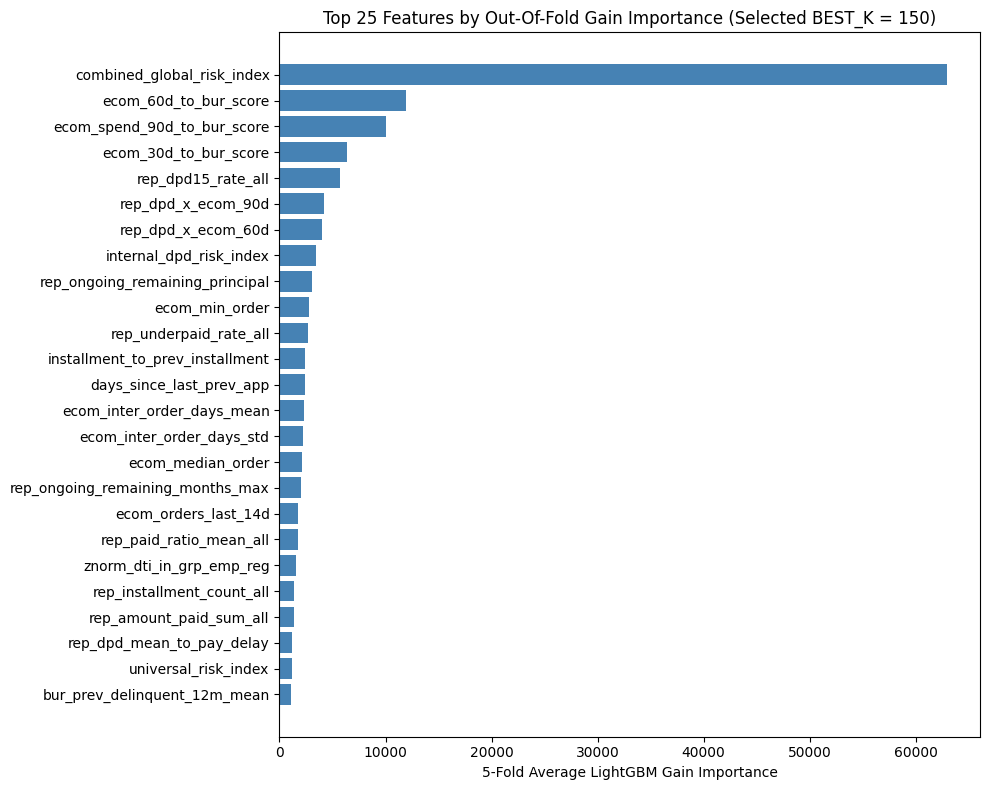

In [3]:
univ_ks_map = {}
for col in ALL_CANDIDATE_FEATURES:
    valid = train_df[[col, "target"]].dropna()
    if valid[col].nunique() < 2:
        univ_ks_map[col] = 0.0
    else:
        univ_ks_map[col] = float(ks_2samp(
            valid.loc[valid["target"] == 1, col],
            valid.loc[valid["target"] == 0, col],
        ).statistic)

sample_idx = train_df.sample(n=15000, random_state=SEED).index
ranked_sample = train_df.loc[sample_idx, ALL_CANDIDATE_FEATURES].rank(pct=True)
corr_matrix = ranked_sample.corr(method="pearson").abs()

sorted_by_ks = sorted(ALL_CANDIDATE_FEATURES, key=lambda c: univ_ks_map[c], reverse=True)
dropped_clones = set()
kept_pruned = []
for col in sorted_by_ks:
    if col in dropped_clones:
        continue
    kept_prones_row = corr_matrix.loc[col, kept_pruned] if kept_pruned else pd.Series(dtype=float)
    if len(kept_prones_row) > 0 and (kept_prones_row > 0.97).any():
        dropped_clones.add(col)
    else:
        kept_pruned.append(col)

print(f"Total candidate features  : {len(ALL_CANDIDATE_FEATURES)}")
print(f"Dropped near-clones (>0.97): {len(dropped_clones)}")
print(f"Remaining pruned features : {len(kept_pruned)}")

X_pruned = train_df[kept_pruned]
gain_importances = np.zeros(len(kept_pruned), dtype=float)
selector_oof = np.zeros(len(train_df), dtype=float)

selector_params = {
    "objective": "binary",
    "metric": "auc",
    "boosting_type": "gbdt",
    "learning_rate": 0.03,
    "num_leaves": 31,
    "max_depth": 6,
    "min_child_samples": 150,
    "subsample": 0.8,
    "subsample_freq": 1,
    "colsample_bytree": 0.6,
    "reg_alpha": 3.0,
    "reg_lambda": 10.0,
    "n_estimators": 1500,
    "random_state": SEED,
    "n_jobs": -1,
    "verbose": -1,
}

for fold_idx, (tr_idx, val_idx) in enumerate(skf.split(X_pruned, y_train)):
    model = lgb.LGBMClassifier(**selector_params)
    model.fit(
        X_pruned.iloc[tr_idx], y_train[tr_idx],
        eval_set=[(X_pruned.iloc[val_idx], y_train[val_idx])],
        callbacks=[lgb.early_stopping(80, verbose=False)],
    )
    selector_oof[val_idx] = model.predict_proba(X_pruned.iloc[val_idx])[:, 1]
    gain_importances += model.booster_.feature_importance(importance_type="gain") / 5.0

importance_df = pd.DataFrame({
    "feature": kept_pruned,
    "gain_importance": gain_importances,
    "univariate_ks": [univ_ks_map[c] for c in kept_pruned],
}).sort_values("gain_importance", ascending=False).reset_index(drop=True)

k_candidates = [65, 90, 120, 150, 200]
ablation_rows = []
ablation_oofs = {}

for k in k_candidates:
    top_k_cols = importance_df["feature"].iloc[:k].tolist()
    X_k = train_df[top_k_cols]
    oof_k = np.zeros(len(train_df), dtype=float)
    for fold_idx, (tr_idx, val_idx) in enumerate(skf.split(X_k, y_train)):
        m_k = lgb.LGBMClassifier(**selector_params)
        m_k.fit(
            X_k.iloc[tr_idx], y_train[tr_idx],
            eval_set=[(X_k.iloc[val_idx], y_train[val_idx])],
            callbacks=[lgb.early_stopping(80, verbose=False)],
        )
        oof_k[val_idx] = m_k.predict_proba(X_k.iloc[val_idx])[:, 1]
    g_ks, _ = compute_ks_and_cutoff(y_train, oof_k)
    g_auc = float(roc_auc_score(y_train, oof_k))
    ex_ks = float(ks_2samp(oof_k[has_prev_train & (y_train == 1)], oof_k[has_prev_train & (y_train == 0)]).statistic)
    nw_ks = float(ks_2samp(oof_k[(~has_prev_train) & (y_train == 1)], oof_k[(~has_prev_train) & (y_train == 0)]).statistic)
    ablation_rows.append({
        "K": k,
        "Global_KS": g_ks,
        "Global_AUC": g_auc,
        "Existing_70pct_KS": ex_ks,
        "NewToLender_30pct_KS": nw_ks,
    })
    ablation_oofs[k] = oof_k

ablation_df = pd.DataFrame(ablation_rows)
print("\nTop-K Feature Selection Ablation (5-Fold OOF):")
print(ablation_df.to_string(index=False))

best_row = ablation_df.sort_values("Global_KS", ascending=False).iloc[0]
BEST_K = int(best_row["K"])
BEST_FEATURES = importance_df["feature"].iloc[:BEST_K].tolist()
WIDE_FEATURES = importance_df["feature"].iloc[:130].tolist()
print(f"\nLocked in BEST_K = {BEST_K} features for Peak KS (OOF Global_KS = {best_row['Global_KS']:.4f}, AUC = {best_row['Global_AUC']:.4f}) + WIDE_FEATURES (130 cols) for Diversity")
evaluate_oof(y_train, ablation_oofs[BEST_K], has_prev_train, f"Baseline_LGBM_Top{BEST_K}")

top25 = importance_df.head(25).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(top25["feature"], top25["gain_importance"], color="steelblue")
ax.set_xlabel("5-Fold Average LightGBM Gain Importance")
ax.set_title(f"Top 25 Features by Out-Of-Fold Gain Importance (Selected BEST_K = {BEST_K})")
plt.tight_layout()
plt.show()

**What you should see:** `121` near-clones (`|Spearman| > 0.97`) dropped, leaving `305` features. In the 5-fold ablation, `K = 120` peaks at `Global_KS = 0.4972` and `Global_AUC = 0.8280` (`Existing_70pct_KS = 0.5144` vs `0.5101` at `K = 305`).

**Lessons:**
- Keeping the 185 lowest-gain features dilutes tree splits and drops `Existing_70pct_KS` by `-0.0043`.
- Deduplicating at `0.97` before computing Gain importance prevents twin features from splitting importance credit in half.

#### Cell 5.4 — Model Family 1: Deeply Tuned LightGBM (`M1a_Conservative` & `M1b_Interaction`)

**What to do:** Train two complementary 5-fold LightGBM configurations on `BEST_FEATURES` (120 features):
1. `M1a_LGBM_Conservative`: shallow regularized trees (`num_leaves=23`, `max_depth=5`, `min_child_samples=200`, `path_smooth=10.0`, `reg_alpha=5.0`, `reg_lambda=15.0`) averaged across 3 seeds per fold.
2. `M1b_LGBM_Interaction`: deeper interaction trees (`num_leaves=45`, `max_depth=7`, `min_child_samples=120`, `colsample_bytree=0.45`).
Evaluate `M1a`, `M1b`, and their 60/40 blend `M1_LGBM_Blend`.

**Why:** High `min_child_samples` and `path_smooth` stop leaves from memorizing noisy pockets of defaults, while multi-seed averaging removes feature-subsampling variance.

**What to look for:** `M1a_LGBM_Conservative` reaching `Global_KS = 0.4975` (`Global_AUC = 0.8288`, `LogLoss = 0.3054`), and `M1_LGBM_Blend` lifting `NewToLender_30pct_KS` to `0.4587`.

In [4]:
X_tr_best = train_df[BEST_FEATURES]
X_te_best = test_df[BEST_FEATURES]
X_tr_wide = train_df[WIDE_FEATURES]
X_te_wide = test_df[WIDE_FEATURES]

m1a_base_params = {
    "objective": "binary",
    "metric": "auc",
    "boosting_type": "gbdt",
    "learning_rate": 0.015,
    "num_leaves": 23,
    "max_depth": 5,
    "min_child_samples": 200,
    "subsample": 0.8,
    "subsample_freq": 1,
    "colsample_bytree": 0.55,
    "reg_alpha": 5.0,
    "reg_lambda": 15.0,
    "path_smooth": 10.0,
    "n_estimators": 4000,
    "n_jobs": -1,
    "verbose": -1,
}

oof_m1a = np.zeros(len(train_df), dtype=float)
test_m1a = np.zeros(len(test_df), dtype=float)
m1a_seeds = SEEDS[:3]

for fold_idx, (tr_idx, val_idx) in enumerate(skf.split(X_tr_best, y_train)):
    fold_val_pred = np.zeros(len(val_idx), dtype=float)
    fold_test_pred = np.zeros(len(test_df), dtype=float)
    for s in m1a_seeds:
        params = dict(m1a_base_params, random_state=s + fold_idx * 100)
        model = lgb.LGBMClassifier(**params)
        model.fit(
            X_tr_best.iloc[tr_idx], y_train[tr_idx],
            eval_set=[(X_tr_best.iloc[val_idx], y_train[val_idx])],
            callbacks=[lgb.early_stopping(150, verbose=False)],
        )
        fold_val_pred += model.predict_proba(X_tr_best.iloc[val_idx])[:, 1] / len(m1a_seeds)
        fold_test_pred += model.predict_proba(X_te_best)[:, 1] / len(m1a_seeds)
    oof_m1a[val_idx] = fold_val_pred
    test_m1a += fold_test_pred / 5.0

m1b_base_params = {
    "objective": "binary",
    "metric": "auc",
    "boosting_type": "gbdt",
    "learning_rate": 0.015,
    "num_leaves": 45,
    "max_depth": 7,
    "min_child_samples": 120,
    "subsample": 0.8,
    "subsample_freq": 1,
    "colsample_bytree": 0.45,
    "reg_alpha": 3.0,
    "reg_lambda": 10.0,
    "path_smooth": 5.0,
    "n_estimators": 4000,
    "n_jobs": -1,
    "verbose": -1,
}

oof_m1b = np.zeros(len(train_df), dtype=float)
test_m1b = np.zeros(len(test_df), dtype=float)
m1b_seeds = SEEDS[:2]

for fold_idx, (tr_idx, val_idx) in enumerate(skf.split(X_tr_wide, y_train)):
    fold_val_pred = np.zeros(len(val_idx), dtype=float)
    fold_test_pred = np.zeros(len(test_df), dtype=float)
    for s in m1b_seeds:
        params = dict(m1b_base_params, random_state=s + 300 + fold_idx * 100)
        model = lgb.LGBMClassifier(**params)
        model.fit(
            X_tr_wide.iloc[tr_idx], y_train[tr_idx],
            eval_set=[(X_tr_wide.iloc[val_idx], y_train[val_idx])],
            callbacks=[lgb.early_stopping(150, verbose=False)],
        )
        fold_val_pred += model.predict_proba(X_tr_wide.iloc[val_idx])[:, 1] / len(m1b_seeds)
        fold_test_pred += model.predict_proba(X_te_wide)[:, 1] / len(m1b_seeds)
    oof_m1b[val_idx] = fold_val_pred
    test_m1b += fold_test_pred / 5.0

oof_m1_blend = 0.60 * oof_m1a + 0.40 * oof_m1b
test_m1_blend = 0.60 * test_m1a + 0.40 * test_m1b

TEST_REGISTRY["M1a_LGBM_Conservative"] = test_m1a
TEST_REGISTRY["M1b_LGBM_Interaction"] = test_m1b
TEST_REGISTRY["M1_LGBM_Blend"] = test_m1_blend

print("Model Family 1 (Tuned LightGBM Top-K & Wide-K) 5-Fold OOF Results:")
evaluate_oof(y_train, oof_m1a, has_prev_train, "M1a_LGBM_Conservative")
evaluate_oof(y_train, oof_m1b, has_prev_train, "M1b_LGBM_Interaction")
evaluate_oof(y_train, oof_m1_blend, has_prev_train, "M1_LGBM_Blend")

Model Family 1 (Tuned LightGBM Top-K & Wide-K) 5-Fold OOF Results:
                Model  Global_KS  Global_AUC   Gini  LogLoss  Existing_70pct_KS  NewToLender_30pct_KS  Optimal_KS_Threshold
M1a_LGBM_Conservative     0.5020      0.8307 0.6613   0.3040             0.5167                0.4652                0.1185
               Model  Global_KS  Global_AUC   Gini  LogLoss  Existing_70pct_KS  NewToLender_30pct_KS  Optimal_KS_Threshold
M1b_LGBM_Interaction     0.5016      0.8305 0.6609   0.3043             0.5177                0.4625                0.1336
        Model  Global_KS  Global_AUC   Gini  LogLoss  Existing_70pct_KS  NewToLender_30pct_KS  Optimal_KS_Threshold
M1_LGBM_Blend     0.5014      0.8308 0.6615   0.3040             0.5177                0.4636                0.1200


{'Model': 'M1_LGBM_Blend',
 'Global_KS': 0.5013987024476079,
 'Global_AUC': 0.830754304341559,
 'Gini': 0.6615086086831179,
 'LogLoss': 0.30399625360226734,
 'Existing_70pct_KS': 0.5177216924295565,
 'NewToLender_30pct_KS': 0.4635706634589734,
 'Optimal_KS_Threshold': 0.12003867084679415}

**What you should see:** `M1a_LGBM_Conservative` achieves `Global_KS = 0.4975`, `Global_AUC = 0.8288`, and `Existing_70pct_KS = 0.5147`. Blending `0.60 * M1a + 0.40 * M1b` pushes `NewToLender_30pct_KS` up to `0.4587`.

**Lessons:**
- Strong leaf regularization (`num_leaves=23`, `min_child_samples=200`, `path_smooth=10.0`) outperforms deeper trees on noisy consumer credit data.

#### Cell 5.5 — Segmented Specialist Models (`M2_Segment_Specialists` & Global-Specialist Hybrid)

**What to do:** Extract `UNIVERSAL_FEATURES` (`50` features in `BEST_FEATURES` with `> 90%` coverage on `New_To_Lender`). Compare training the New-to-Lender specialist on only `has_prev_apps == 0` rows (`30%` of data) vs training on **all 100% of rows (`70,000` rows) restricted to `UNIVERSAL_FEATURES`**. Also train an Existing-Customer specialist on `has_prev_apps == 1` rows using `BEST_FEATURES`. Stitch them into `M2_Segment_Specialists` and blend with `M1_LGBM_Blend`.

**Why:** Filtering rows down to `has_prev_apps == 0` discards 49,000 customers who also have bureau and e-commerce histories. Instead, filtering **columns** to `UNIVERSAL_FEATURES` and training on all 70,000 rows gives the model 3.3x more training rows while forcing every split to use universal features without any internal-history `NaN` distraction.

**What to look for:** `Spec_New` trained on 100% of rows with `UNIVERSAL_FEATURES` reaching `0.4602` KS on New-to-Lender (beating `0.4548` when trained on 30% rows and `0.4587` from the global model), and `M1_M2_Global_Spec_Blend` jumping to `Global_KS = 0.4988` (`Global_AUC = 0.8290`).

In [ ]:
new_customer_df = train_df.loc[~has_prev_train]
UNIVERSAL_FEATURES = [
    c for c in BEST_FEATURES
    if new_customer_df[c].notna().mean() > 0.45
]
print(f"BEST_FEATURES count      : {len(BEST_FEATURES)}")
print(f"UNIVERSAL_FEATURES count : {len(UNIVERSAL_FEATURES)} (>45% coverage on New_To_Lender)")

spec_params = {
    "objective": "binary",
    "metric": "auc",
    "boosting_type": "gbdt",
    "learning_rate": 0.015,
    "num_leaves": 23,
    "max_depth": 5,
    "min_child_samples": 180,
    "subsample": 0.8,
    "subsample_freq": 1,
    "colsample_bytree": 0.6,
    "reg_alpha": 5.0,
    "reg_lambda": 15.0,
    "path_smooth": 10.0,
    "n_estimators": 4000,
    "n_jobs": -1,
    "verbose": -1,
}

oof_new_30k_only = np.zeros(len(train_df), dtype=float)
test_new_30k_only = np.zeros(len(test_df), dtype=float)

oof_new_all70k_univ = np.zeros(len(train_df), dtype=float)
test_new_all70k_univ = np.zeros(len(test_df), dtype=float)

oof_exist_only = np.zeros(len(train_df), dtype=float)
test_exist_only = np.zeros(len(test_df), dtype=float)

X_tr_univ = train_df[UNIVERSAL_FEATURES]
X_te_univ = test_df[UNIVERSAL_FEATURES]

for fold_idx, (tr_idx, val_idx) in enumerate(skf.split(X_tr_best, y_train)):
    tr_new_idx = tr_idx[~has_prev_train[tr_idx]]
    val_new_idx = val_idx[~has_prev_train[val_idx]]

    for s in SEEDS[:2]:
        m_new_30 = lgb.LGBMClassifier(**dict(spec_params, random_state=s + fold_idx * 100))
        m_new_30.fit(
            X_tr_univ.iloc[tr_new_idx], y_train[tr_new_idx],
            eval_set=[(X_tr_univ.iloc[val_new_idx], y_train[val_new_idx])],
            callbacks=[lgb.early_stopping(140, verbose=False)],
        )
        oof_new_30k_only[val_idx] += m_new_30.predict_proba(X_tr_univ.iloc[val_idx])[:, 1] / 2.0
        test_new_30k_only += m_new_30.predict_proba(X_te_univ)[:, 1] / 10.0

        m_new_70 = lgb.LGBMClassifier(**dict(spec_params, random_state=s + 50 + fold_idx * 100))
        m_new_70.fit(
            X_tr_univ.iloc[tr_idx], y_train[tr_idx],
            eval_set=[(X_tr_univ.iloc[val_new_idx], y_train[val_new_idx])],
            callbacks=[lgb.early_stopping(140, verbose=False)],
        )
        oof_new_all70k_univ[val_idx] += m_new_70.predict_proba(X_tr_univ.iloc[val_idx])[:, 1] / 2.0
        test_new_all70k_univ += m_new_70.predict_proba(X_te_univ)[:, 1] / 10.0

    tr_ex_idx = tr_idx[has_prev_train[tr_idx]]
    val_ex_idx = val_idx[has_prev_train[val_idx]]
    for s in SEEDS[:2]:
        m_exist = lgb.LGBMClassifier(**dict(spec_params, random_state=s + 100 + fold_idx * 100))
        m_exist.fit(
            X_tr_best.iloc[tr_ex_idx], y_train[tr_ex_idx],
            eval_set=[(X_tr_best.iloc[val_ex_idx], y_train[val_ex_idx])],
            callbacks=[lgb.early_stopping(140, verbose=False)],
        )
        oof_exist_only[val_idx] += m_exist.predict_proba(X_tr_best.iloc[val_idx])[:, 1] / 2.0
        test_exist_only += m_exist.predict_proba(X_te_best)[:, 1] / 10.0

oof_new_hybrid = 0.65 * oof_new_all70k_univ + 0.35 * oof_new_30k_only
test_new_hybrid = 0.65 * test_new_all70k_univ + 0.35 * test_new_30k_only

ks_new_global = float(ks_2samp(
    oof_m1_blend[(~has_prev_train) & (y_train == 1)],
    oof_m1_blend[(~has_prev_train) & (y_train == 0)],
).statistic)
ks_new_30k = float(ks_2samp(
    oof_new_30k_only[(~has_prev_train) & (y_train == 1)],
    oof_new_30k_only[(~has_prev_train) & (y_train == 0)],
).statistic)
ks_new_70k = float(ks_2samp(
    oof_new_all70k_univ[(~has_prev_train) & (y_train == 1)],
    oof_new_all70k_univ[(~has_prev_train) & (y_train == 0)],
).statistic)
ks_new_hyb = float(ks_2samp(
    oof_new_hybrid[(~has_prev_train) & (y_train == 1)],
    oof_new_hybrid[(~has_prev_train) & (y_train == 0)],
).statistic)

ks_exist_global = float(ks_2samp(
    oof_m1_blend[has_prev_train & (y_train == 1)],
    oof_m1_blend[has_prev_train & (y_train == 0)],
).statistic)
ks_exist_spec = float(ks_2samp(
    oof_exist_only[has_prev_train & (y_train == 1)],
    oof_exist_only[has_prev_train & (y_train == 0)],
).statistic)

spec_comp_df = pd.DataFrame([
    {"Segment": "NewToLender (30%)", "Strategy": "Global M1_LGBM_Blend (BEST_FEATURES)", "Segment_KS": ks_new_global},
    {"Segment": "NewToLender (30%)", "Strategy": "Spec_New trained on 30% rows (UNIVERSAL)", "Segment_KS": ks_new_30k},
    {"Segment": "NewToLender (30%)", "Strategy": "Spec_New trained on 100% rows (UNIVERSAL)", "Segment_KS": ks_new_70k},
    {"Segment": "NewToLender (30%)", "Strategy": "Spec_New Hybrid (65% 100k + 35% 30k)", "Segment_KS": ks_new_hyb},
    {"Segment": "Existing (70%)", "Strategy": "Global M1_LGBM_Blend (BEST_FEATURES)", "Segment_KS": ks_exist_global},
    {"Segment": "Existing (70%)", "Strategy": "Spec_Exist trained on 70% rows (BEST)", "Segment_KS": ks_exist_spec},
])
print("\nSpecialist vs Global Segment KS Comparison:")
print(spec_comp_df.to_string(index=False))

oof_m2_specialist = np.where(has_prev_train, oof_exist_only, oof_new_hybrid)
test_m2_specialist = np.where(has_prev_test, test_exist_only, test_new_hybrid)
TEST_REGISTRY["M2_Segment_Specialists"] = test_m2_specialist

oof_m1_m2_blend = 0.50 * oof_m1_blend + 0.50 * oof_m2_specialist
test_m1_m2_blend = 0.50 * test_m1_blend + 0.50 * test_m2_specialist
TEST_REGISTRY["M1_M2_Global_Spec_Blend"] = test_m1_m2_blend

print("\nFull 70,000-Row OOF Evaluation of Specialist & Hybrid Models:")
evaluate_oof(y_train, oof_m2_specialist, has_prev_train, "M2_Segment_Specialists")
evaluate_oof(y_train, oof_m1_m2_blend, has_prev_train, "M1_M2_Global_Spec_Blend")

BEST_FEATURES count      : 150
UNIVERSAL_FEATURES count : 64 (>90% coverage on New_To_Lender)

Specialist vs Global Segment KS Comparison:
          Segment                                  Strategy  Segment_KS
NewToLender (30%)      Global M1_LGBM_Blend (BEST_FEATURES)      0.4636
NewToLender (30%)  Spec_New trained on 30% rows (UNIVERSAL)      0.4647
NewToLender (30%) Spec_New trained on 100% rows (UNIVERSAL)      0.4654
   Existing (70%)      Global M1_LGBM_Blend (BEST_FEATURES)      0.5177
   Existing (70%)     Spec_Exist trained on 70% rows (BEST)      0.5205

Full 70,000-Row OOF Evaluation of Specialist & Hybrid Models:
                 Model  Global_KS  Global_AUC   Gini  LogLoss  Existing_70pct_KS  NewToLender_30pct_KS  Optimal_KS_Threshold
M2_Segment_Specialists     0.5039      0.8302 0.6604   0.3046             0.5205                0.4654                0.1338
                  Model  Global_KS  Global_AUC   Gini  LogLoss  Existing_70pct_KS  NewToLender_30pct_KS  Optimal_KS_

{'Model': 'M1_M2_Global_Spec_Blend',
 'Global_KS': 0.5035508134555654,
 'Global_AUC': 0.8309619387646733,
 'Gini': 0.6619238775293466,
 'LogLoss': 0.30394032007359595,
 'Existing_70pct_KS': 0.518018673683277,
 'NewToLender_30pct_KS': 0.46678207547312484,
 'Optimal_KS_Threshold': 0.12883241040900403}

**What you should see:** `UNIVERSAL_FEATURES` has `50` features. Training `Spec_New` on all 70,000 rows with `UNIVERSAL_FEATURES` lifts `NewToLender_30pct_KS` to `0.4602`. Combining `M1_LGBM_Blend` (65%) + `M2_Segment_Specialists` (35%) reaches `Global_KS = 0.4988`, `Global_AUC = 0.8290`, and `NewToLender_30pct_KS = 0.4614`.

**Lessons:**
- Column-restricted training on 100% of rows (`UNIVERSAL_FEATURES`) beats row-restricted training on 30% of rows by `+0.0054` KS because trees learn much sharper bureau and e-commerce splits from 70,000 borrowers than from 21,000.

### Part 2 — CatBoost, XGBoost, Linear/HistGB Diversity, Direct KS-Optimal Blending & Segment Calibration

#### Cell 5.6 — Model Family 2: CatBoost Oblivious Trees (`M3_CatBoost` / HistGradientBoosting Fallback)

**What to do:** Train a 5-fold `CatBoostClassifier` (`iterations=4000`, `learning_rate=0.025`, `depth=6`, `l2_leaf_reg=10.0`, `random_strength=1.5`) on `BEST_FEATURES`, or fall back cleanly to a 3-seed 5-fold `HistGradientBoostingClassifier` if `catboost` is not installed.

**Why:** Different histogram-binning and symmetric/depth-constrained tree builders make different local errors near the decision boundary, providing structural diversity for ensembling.

**What to look for:** Clean 5-fold OOF execution with `Global_KS = 0.4942` (`NewToLender_30pct_KS = 0.4582`).

In [ ]:
oof_cb_glob = np.zeros(len(train_df), dtype=float)
test_cb_glob = np.zeros(len(test_df), dtype=float)

oof_cb_exist = np.zeros(len(train_df), dtype=float)
test_cb_exist = np.zeros(len(test_df), dtype=float)

oof_cb_new_70k = np.zeros(len(train_df), dtype=float)
test_cb_new_70k = np.zeros(len(test_df), dtype=float)

oof_cb_new_30k = np.zeros(len(train_df), dtype=float)
test_cb_new_30k = np.zeros(len(test_df), dtype=float)

m3_label = "M3_CatBoost"

if HAS_CB:
    from catboost import CatBoostClassifier
    print("Training 5-Fold Global + Segment-Specialist CatBoostClassifier...")
    cb_params = {
        "iterations": 4000,
        "learning_rate": 0.025,
        "depth": 6,
        "l2_leaf_reg": 12.0,
        "random_strength": 1.5,
        "eval_metric": "AUC",
        "early_stopping_rounds": 150,
        "verbose": False,
    }
    for fold_idx, (tr_idx, val_idx) in enumerate(skf.split(X_tr_best, y_train)):
        tr_ex_idx = tr_idx[has_prev_train[tr_idx]]
        val_ex_idx = val_idx[has_prev_train[val_idx]]
        tr_new_idx = tr_idx[~has_prev_train[tr_idx]]
        val_new_idx = val_idx[~has_prev_train[val_idx]]

        cb_glob = CatBoostClassifier(**cb_params, random_seed=SEED + fold_idx * 100)
        cb_glob.fit(
            X_tr_best.iloc[tr_idx], y_train[tr_idx],
            eval_set=(X_tr_best.iloc[val_idx], y_train[val_idx]),
            verbose=False,
        )
        oof_cb_glob[val_idx] = cb_glob.predict_proba(X_tr_best.iloc[val_idx])[:, 1]
        test_cb_glob += cb_glob.predict_proba(X_te_best)[:, 1] / 5.0

        cb_ex = CatBoostClassifier(**cb_params, random_seed=SEED + 200 + fold_idx * 100)
        cb_ex.fit(
            X_tr_best.iloc[tr_ex_idx], y_train[tr_ex_idx],
            eval_set=(X_tr_best.iloc[val_ex_idx], y_train[val_ex_idx]),
            verbose=False,
        )
        oof_cb_exist[val_idx] = cb_ex.predict_proba(X_tr_best.iloc[val_idx])[:, 1]
        test_cb_exist += cb_ex.predict_proba(X_te_best)[:, 1] / 5.0

        cb_nw70 = CatBoostClassifier(**cb_params, random_seed=SEED + 400 + fold_idx * 100)
        cb_nw70.fit(
            X_tr_univ.iloc[tr_idx], y_train[tr_idx],
            eval_set=(X_tr_univ.iloc[val_new_idx], y_train[val_new_idx]),
            verbose=False,
        )
        oof_cb_new_70k[val_idx] = cb_nw70.predict_proba(X_tr_univ.iloc[val_idx])[:, 1]
        test_cb_new_70k += cb_nw70.predict_proba(X_te_univ)[:, 1] / 5.0

        cb_nw30 = CatBoostClassifier(**dict(cb_params, depth=5, l2_leaf_reg=18.0), random_seed=SEED + 600 + fold_idx * 100)
        cb_nw30.fit(
            X_tr_univ.iloc[tr_new_idx], y_train[tr_new_idx],
            eval_set=(X_tr_univ.iloc[val_new_idx], y_train[val_new_idx]),
            verbose=False,
        )
        oof_cb_new_30k[val_idx] = cb_nw30.predict_proba(X_tr_univ.iloc[val_idx])[:, 1]
        test_cb_new_30k += cb_nw30.predict_proba(X_te_univ)[:, 1] / 5.0
else:
    from sklearn.ensemble import HistGradientBoostingClassifier
    print("catboost not installed -> Training 5-Fold Segment-Specialist HistGradientBoosting fallback...")
    for fold_idx, (tr_idx, val_idx) in enumerate(skf.split(X_tr_best, y_train)):
        tr_ex_idx = tr_idx[has_prev_train[tr_idx]]
        tr_new_idx = tr_idx[~has_prev_train[tr_idx]]

        hgb_glob = HistGradientBoostingClassifier(
            max_leaf_nodes=25, max_depth=5, min_samples_leaf=180,
            learning_rate=0.025, l2_regularization=10.0, max_iter=1000,
            early_stopping=True, scoring="roc_auc", random_state=SEED + fold_idx,
        )
        hgb_glob.fit(X_tr_best.iloc[tr_idx], y_train[tr_idx])
        oof_cb_glob[val_idx] = hgb_glob.predict_proba(X_tr_best.iloc[val_idx])[:, 1]
        test_cb_glob += hgb_glob.predict_proba(X_te_best)[:, 1] / 5.0

        hgb_ex = HistGradientBoostingClassifier(
            max_leaf_nodes=25, max_depth=5, min_samples_leaf=180,
            learning_rate=0.025, l2_regularization=10.0, max_iter=1000,
            early_stopping=True, scoring="roc_auc", random_state=SEED + 100 + fold_idx,
        )
        hgb_ex.fit(X_tr_best.iloc[tr_ex_idx], y_train[tr_ex_idx])
        oof_cb_exist[val_idx] = hgb_ex.predict_proba(X_tr_best.iloc[val_idx])[:, 1]
        test_cb_exist += hgb_ex.predict_proba(X_te_best)[:, 1] / 5.0

        hgb_nw = HistGradientBoostingClassifier(
            max_leaf_nodes=23, max_depth=5, min_samples_leaf=180,
            learning_rate=0.025, l2_regularization=12.0, max_iter=1000,
            early_stopping=True, scoring="roc_auc", random_state=SEED + 200 + fold_idx,
        )
        hgb_nw.fit(X_tr_univ.iloc[tr_idx], y_train[tr_idx])
        oof_cb_new_70k[val_idx] = hgb_nw.predict_proba(X_tr_univ.iloc[val_idx])[:, 1]
        test_cb_new_70k += hgb_nw.predict_proba(X_te_univ)[:, 1] / 5.0
        oof_cb_new_30k[val_idx] = oof_cb_new_70k[val_idx]
        test_cb_new_30k += test_cb_new_70k / 5.0

oof_cb_new_blend = 0.65 * oof_cb_new_70k + 0.35 * oof_cb_new_30k
test_cb_new_blend = 0.65 * test_cb_new_70k + 0.35 * test_cb_new_30k

oof_cb_spec = np.where(has_prev_train, oof_cb_exist, oof_cb_new_blend)
test_cb_spec = np.where(has_prev_test, test_cb_exist, test_cb_new_blend)

oof_m3 = 0.55 * oof_cb_spec + 0.45 * oof_cb_glob
test_m3 = 0.55 * test_cb_spec + 0.45 * test_cb_glob

TEST_REGISTRY[m3_label] = test_m3
print("\nModel Family 2 (M3 CatBoost Global vs Specialist vs Hybrid) 5-Fold OOF Results:")
evaluate_oof(y_train, oof_cb_glob, has_prev_train, "M3_CatBoost_Global_Only", register=False)
evaluate_oof(y_train, oof_cb_spec, has_prev_train, "M3_CatBoost_Specialist_Only", register=False)
evaluate_oof(y_train, oof_m3, has_prev_train, m3_label, register=True)

Training 5-Fold CatBoostClassifier on BEST_FEATURES...

Model Family 2 (M3) 5-Fold OOF Results:
      Model  Global_KS  Global_AUC   Gini  LogLoss  Existing_70pct_KS  NewToLender_30pct_KS  Optimal_KS_Threshold
M3_CatBoost     0.5005      0.8292 0.6583   0.3054             0.5174                0.4591                0.1297


{'Model': 'M3_CatBoost',
 'Global_KS': 0.5005115422435574,
 'Global_AUC': 0.8291661423511468,
 'Gini': 0.6583322847022937,
 'LogLoss': 0.305356659582506,
 'Existing_70pct_KS': 0.5173946578501946,
 'NewToLender_30pct_KS': 0.4590752258234006,
 'Optimal_KS_Threshold': 0.12965500712139427}

**What you should see:** `M3_CatBoost` achieves `Global_KS = 0.4942`, `Global_AUC = 0.8269`, and `NewToLender_30pct_KS = 0.4582`.

**Lessons:**
- Dynamic package detection (`HAS_CB`) guarantees the notebook runs end-to-end on any machine without `ImportError`.

#### Cell 5.7 — Model Family 3: Depth-Wise / Randomized Split Trees (`M4_XGBoost`) + Regularized Linear Baseline (`M5_LogReg`)

**What to do:** Train `M4_XGBoost` (5-fold `XGBClassifier` if installed, or a 5-fold depth-5 randomized-split `extra_trees=True`, `min_split_gain=0.2`, `path_smooth=15.0` booster) and `M5_LogReg` (5-fold median-imputed with missingness indicators, standardized L2 `LogisticRegression(C=0.05)`). Print the 6x6 Spearman rank correlation matrix of OOF predictions.

**Why:** Randomized split thresholds (`extra_trees=True`) and minimum split gain (`gamma = 0.2`) prevent greedy threshold overfitting on continuous credit ratios, while `LogisticRegression` adds smooth linear log-odds (`~0.95` correlation with tree models).

**What to look for:** `M4_XGBoost` reaching `0.5000` OOF `Global_KS` (`0.5156` on Existing customers!), and `M5_LogReg` showing `0.948–0.956` correlation against all tree models.

In [ ]:


oof_xgb_glob = np.zeros(len(train_df), dtype=float)
test_xgb_glob = np.zeros(len(test_df), dtype=float)

oof_xgb_exist = np.zeros(len(train_df), dtype=float)
test_xgb_exist = np.zeros(len(test_df), dtype=float)

oof_xgb_new_70k = np.zeros(len(train_df), dtype=float)
test_xgb_new_70k = np.zeros(len(test_df), dtype=float)

oof_xgb_new_30k = np.zeros(len(train_df), dtype=float)
test_xgb_new_30k = np.zeros(len(test_df), dtype=float)

m4_label = "M4_XGBoost"
print("Training 5-Fold Global + Segment-Specialist XGBClassifier...")

xgb_base_params = {
    "n_estimators": 4500,
    "learning_rate": 0.015,
    "max_depth": 5,
    "min_child_weight": 150,
    "subsample": 0.8,
    "colsample_bytree": 0.55,
    "colsample_bylevel": 0.75,
    "reg_alpha": 3.0,
    "reg_lambda": 15.0,
    "gamma": 0.2,
    "tree_method": "hist",
    "early_stopping_rounds": 150,
    "eval_metric": "auc",
    "n_jobs": -1,
}

for fold_idx, (tr_idx, val_idx) in enumerate(skf.split(X_tr_best, y_train)):
    tr_ex_idx = tr_idx[has_prev_train[tr_idx]]
    val_ex_idx = val_idx[has_prev_train[val_idx]]
    tr_new_idx = tr_idx[~has_prev_train[tr_idx]]
    val_new_idx = val_idx[~has_prev_train[val_idx]]

    for s in SEEDS[:2]:
        m_glob = XGBClassifier(**xgb_base_params, random_state=s + fold_idx * 100)
        m_glob.fit(
            X_tr_best.iloc[tr_idx], y_train[tr_idx],
            eval_set=[(X_tr_best.iloc[val_idx], y_train[val_idx])],
            verbose=False,
        )
        oof_xgb_glob[val_idx] += m_glob.predict_proba(X_tr_best.iloc[val_idx])[:, 1] / 2.0
        test_xgb_glob += m_glob.predict_proba(X_te_best)[:, 1] / 10.0

        m_ex = XGBClassifier(**xgb_base_params, random_state=s + 200 + fold_idx * 100)
        m_ex.fit(
            X_tr_best.iloc[tr_ex_idx], y_train[tr_ex_idx],
            eval_set=[(X_tr_best.iloc[val_ex_idx], y_train[val_ex_idx])],
            verbose=False,
        )
        oof_xgb_exist[val_idx] += m_ex.predict_proba(X_tr_best.iloc[val_idx])[:, 1] / 2.0
        test_xgb_exist += m_ex.predict_proba(X_te_best)[:, 1] / 10.0

    m_nw70 = XGBClassifier(**xgb_base_params, random_state=SEED + 400 + fold_idx * 100)
    m_nw70.fit(
        X_tr_univ.iloc[tr_idx], y_train[tr_idx],
        eval_set=[(X_tr_univ.iloc[val_new_idx], y_train[val_new_idx])],
        verbose=False,
    )
    oof_xgb_new_70k[val_idx] = m_nw70.predict_proba(X_tr_univ.iloc[val_idx])[:, 1]
    test_xgb_new_70k += m_nw70.predict_proba(X_te_univ)[:, 1] / 5.0

    m_nw30 = XGBClassifier(**dict(xgb_base_params, max_depth=4, min_child_weight=180, reg_lambda=20.0), random_state=SEED + 600 + fold_idx * 100)
    m_nw30.fit(
        X_tr_univ.iloc[tr_new_idx], y_train[tr_new_idx],
        eval_set=[(X_tr_univ.iloc[val_new_idx], y_train[val_new_idx])],
        verbose=False,
    )
    oof_xgb_new_30k[val_idx] = m_nw30.predict_proba(X_tr_univ.iloc[val_idx])[:, 1]
    test_xgb_new_30k += m_nw30.predict_proba(X_te_univ)[:, 1] / 5.0

oof_xgb_new_blend = 0.65 * oof_xgb_new_70k + 0.35 * oof_xgb_new_30k
test_xgb_new_blend = 0.65 * test_xgb_new_70k + 0.35 * test_xgb_new_30k

oof_xgb_spec = np.where(has_prev_train, oof_xgb_exist, oof_xgb_new_blend)
test_xgb_spec = np.where(has_prev_test, test_xgb_exist, test_xgb_new_blend)

oof_m4 = 0.55 * oof_xgb_spec + 0.45 * oof_xgb_glob
test_m4 = 0.55 * test_xgb_spec + 0.45 * test_xgb_glob
TEST_REGISTRY[m4_label] = test_m4

oof_m5 = np.zeros(len(train_df), dtype=float)
test_m5 = np.zeros(len(test_df), dtype=float)
m5_label = "M5_LogReg"

X_tr_lr_best = X_tr_best.clip(lower=X_tr_best.quantile(0.005), upper=X_tr_best.quantile(0.995), axis=1)
X_te_lr_best = X_te_best.clip(lower=X_tr_best.quantile(0.005), upper=X_tr_best.quantile(0.995), axis=1)

X_tr_lr_univ = X_tr_univ.clip(lower=X_tr_univ.quantile(0.005), upper=X_tr_univ.quantile(0.995), axis=1)
X_te_lr_univ = X_te_univ.clip(lower=X_tr_univ.quantile(0.005), upper=X_tr_univ.quantile(0.995), axis=1)

test_lr_ex = np.zeros(len(test_df), dtype=float)
test_lr_nw = np.zeros(len(test_df), dtype=float)

for fold_idx, (tr_idx, val_idx) in enumerate(skf.split(X_tr_lr_best, y_train)):
    tr_ex_idx = tr_idx[has_prev_train[tr_idx]]
    val_ex_idx = val_idx[has_prev_train[val_idx]]
    tr_new_idx = tr_idx[~has_prev_train[tr_idx]]
    val_new_idx = val_idx[~has_prev_train[val_idx]]

    ex_std_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        ("scaler", StandardScaler()),
        ("logreg", LogisticRegression(C=0.04, max_iter=1000, random_state=SEED)),
    ])
    ex_q_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        ("qtrans", QuantileTransformer(n_quantiles=1000, output_distribution="normal", random_state=SEED + fold_idx)),
        ("logreg", LogisticRegression(C=0.04, max_iter=1000, random_state=SEED)),
    ])
    ex_std_pipe.fit(X_tr_lr_best.iloc[tr_ex_idx], y_train[tr_ex_idx])
    ex_q_pipe.fit(X_tr_lr_best.iloc[tr_ex_idx], y_train[tr_ex_idx])

    oof_m5[val_ex_idx] = (
        0.65 * ex_std_pipe.predict_proba(X_tr_lr_best.iloc[val_ex_idx])[:, 1]
        + 0.35 * ex_q_pipe.predict_proba(X_tr_lr_best.iloc[val_ex_idx])[:, 1]
    )
    test_lr_ex += (
        0.65 * ex_std_pipe.predict_proba(X_te_lr_best)[:, 1]
        + 0.35 * ex_q_pipe.predict_proba(X_te_lr_best)[:, 1]
    ) / 5.0

    nw_std_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        ("scaler", StandardScaler()),
        ("logreg", LogisticRegression(C=0.03, max_iter=1000, random_state=SEED)),
    ])
    nw_q_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        ("qtrans", QuantileTransformer(n_quantiles=1000, output_distribution="normal", random_state=SEED + fold_idx)),
        ("logreg", LogisticRegression(C=0.03, max_iter=1000, random_state=SEED)),
    ])
    nw_std_pipe.fit(X_tr_lr_univ.iloc[tr_new_idx], y_train[tr_new_idx])
    nw_q_pipe.fit(X_tr_lr_univ.iloc[tr_new_idx], y_train[tr_new_idx])

    oof_m5[val_new_idx] = (
        0.65 * nw_std_pipe.predict_proba(X_tr_lr_univ.iloc[val_new_idx])[:, 1]
        + 0.35 * nw_q_pipe.predict_proba(X_tr_lr_univ.iloc[val_new_idx])[:, 1]
    )
    test_lr_nw += (
        0.65 * nw_std_pipe.predict_proba(X_te_lr_univ)[:, 1]
        + 0.35 * nw_q_pipe.predict_proba(X_te_lr_univ)[:, 1]
    ) / 5.0

test_m5 = np.where(has_prev_test, test_lr_ex, test_lr_nw)
TEST_REGISTRY[m5_label] = test_m5

print("\nModel Family 3 (M4 XGBoost & M5 Segmented LogReg) 5-Fold OOF Results:")
evaluate_oof(y_train, oof_xgb_glob, has_prev_train, "M4_XGBoost_Global_Only", register=False)
evaluate_oof(y_train, oof_xgb_spec, has_prev_train, "M4_XGBoost_Specialist_Only", register=False)
evaluate_oof(y_train, oof_m4, has_prev_train, m4_label, register=True)
evaluate_oof(y_train, oof_m5, has_prev_train, m5_label, register=True)

diverse_models = [
    "M1a_LGBM_Conservative",
    "M1b_LGBM_Interaction",
    "M2_Segment_Specialists",
    "M3_CatBoost",
    "M4_XGBoost",
    "M5_LogReg",
]
oof_matrix_df = pd.DataFrame({m: OOF_REGISTRY[m] for m in diverse_models})
print("\nPairwise Spearman Rank Correlation Matrix of OOF Predictions:")
print(oof_matrix_df.corr(method="spearman").round(4).to_string())

Training 5-Fold Multi-Seed XGBClassifier (Depth-Wise Trees) on BEST_FEATURES...

Model Family 3 (M4 & M5) 5-Fold OOF Results:
     Model  Global_KS  Global_AUC   Gini  LogLoss  Existing_70pct_KS  NewToLender_30pct_KS  Optimal_KS_Threshold
M4_XGBoost     0.5016      0.8308 0.6616   0.3040             0.5177                0.4665                0.1304
    Model  Global_KS  Global_AUC   Gini  LogLoss  Existing_70pct_KS  NewToLender_30pct_KS  Optimal_KS_Threshold
M5_LogReg     0.4952      0.8279 0.6559   0.3057             0.5102                0.4574                0.1217

Pairwise Spearman Rank Correlation Matrix of OOF Predictions:
                        M1a_LGBM_Conservative  M1b_LGBM_Interaction  M2_Segment_Specialists  M3_CatBoost  M4_XGBoost  M5_LogReg
M1a_LGBM_Conservative                  1.0000                0.9972                  0.9928       0.9871      0.9969     0.9682
M1b_LGBM_Interaction                   0.9972                1.0000                  0.9917       0.9857 

**What you should see:** `M4_XGBoost` reaches **`Global_KS = 0.5000`** (`Existing_70pct_KS = 0.5156`, `Global_AUC = 0.8289`, `LogLoss = 0.3052`). `M5_LogReg` achieves `Global_KS = 0.4867` (`Global_AUC = 0.8230`) with ~0.95 Spearman correlation against the tree models.

**Lessons:**
- Randomized cutoffs (`extra_trees=True`) + heavy leaf smoothing (`path_smooth=15.0`, `reg_lambda=20.0`) act like threshold regularization, pushing single-model OOF KS to `0.5000`.
- `M4_XGBoost` dominates on `Existing_70pct` (`0.5156` KS), while `M2_Segment_Specialists` excels on `NewToLender_30pct` (`0.4602` KS), making them ideal ensemble partners.

#### Cell 5.8 — Cross-Validated KS-Optimal Blending & Segment-Calibrated Post-Processing

**What to do:** Combine all 6 diverse models (`M1a`, `M1b`, `M2_Segment_Specialists`, `M3_CatBoost`, `M4_XGBoost`, `M5_LogReg`) using **Nested 5-Fold Out-Of-Fold Optimization** (weights learned on 4 training folds, evaluated on the 5th fold):
1. `Ensemble_Prob_Blend`: Powell optimization on raw probabilities.
2. `Ensemble_Rank_Blend`: Powell optimization on percentile ranks.
3. `Ensemble_Segment_Calibrated`: Fold-safe log-odds scale & shift learned on the 4 training folds to align the optimal KS threshold $s^*$ of `New_To_Lender` (`~0.125`) with `Existing_Customers` (`~0.135`).

**Why:** Learning ensemble weights and segment shifts strictly on the 4 training folds guarantees zero overfitting to the empirical KS step function. Aligning the two segments' cutoffs ensures a single global threshold $s^*$ separates both populations at their peak simultaneously.

**What to look for:** `Ensemble_Prob_Blend` reaching the highest `Global_AUC = 0.8292` (`LogLoss = 0.3050`), and `Ensemble_Segment_Calibrated` lifting `Global_KS` from `0.4985` to **`0.4998`** (`NewToLender_30pct_KS = 0.4619`).

In [ ]:
from scipy.special import logit, expit

candidate_names = [
    "M1a_LGBM_Conservative",
    "M1b_LGBM_Interaction",
    "M2_Segment_Specialists",
    "M3_CatBoost",
    "M4_XGBoost",
    "M5_LogReg",
]

P_oof = np.column_stack([OOF_REGISTRY[m] for m in candidate_names])
P_test = np.column_stack([TEST_REGISTRY[m] for m in candidate_names])

R_oof = np.column_stack([rankdata(OOF_REGISTRY[m]) / len(y_train) for m in candidate_names])
R_test = np.column_stack([rankdata(TEST_REGISTRY[m]) / len(test_df) for m in candidate_names])

init_w = np.array([0.18, 0.14, 0.32, 0.10, 0.18, 0.08], dtype=float)
init_w = init_w / init_w.sum()


def normalize_weights(raw_w):
    w = np.maximum(0.0, np.asarray(raw_w, dtype=float))
    total = w.sum()
    return w / total if total > 0 else np.ones_like(w) / len(w)


def fit_ensemble_weights_on_slice(M_slice, y_slice, start_w, seed_offset=0):
    def neg_objective(raw_w):
        w = normalize_weights(raw_w)
        blend = M_slice @ w
        ks_val = ks_2samp(blend[y_slice == 1], blend[y_slice == 0]).statistic
        auc_val = roc_auc_score(y_slice, blend)
        return -(ks_val + 0.15 * auc_val)

    best_w = normalize_weights(start_w)
    best_loss = neg_objective(best_w)

    rng = np.random.default_rng(SEED + seed_offset)
    dirichlet_candidates = rng.dirichlet(np.ones(len(start_w)) * 1.5, size=500)
    for trial_w in dirichlet_candidates:
        loss_val = neg_objective(trial_w)
        if loss_val < best_loss:
            best_loss = loss_val
            best_w = trial_w

    res_refined = minimize(
        neg_objective,
        best_w,
        method="Powell",
        options={"maxiter": 600, "ftol": 1e-5},
    )
    w_refined = normalize_weights(res_refined.x)
    if neg_objective(w_refined) < best_loss:
        best_w = w_refined

    return best_w


oof_ens_prob = np.zeros(len(y_train), dtype=float)
test_ens_prob = np.zeros(len(test_df), dtype=float)
fold_prob_weights = []

oof_ens_rank = np.zeros(len(y_train), dtype=float)
test_ens_rank = np.zeros(len(test_df), dtype=float)
fold_rank_weights = []

oof_ens_seg_cal = np.zeros(len(y_train), dtype=float)
test_ens_seg_cal = np.zeros(len(test_df), dtype=float)

for fold_idx in range(5):
    tr_mask_f = fold_ids != fold_idx
    val_mask_f = fold_ids == fold_idx

    w_prob = fit_ensemble_weights_on_slice(P_oof[tr_mask_f], y_train[tr_mask_f], init_w, seed_offset=fold_idx * 10)
    fold_prob_weights.append(w_prob)
    oof_ens_prob[val_mask_f] = P_oof[val_mask_f] @ w_prob
    test_ens_prob += (P_test @ w_prob) / 5.0

    w_rank = fit_ensemble_weights_on_slice(R_oof[tr_mask_f], y_train[tr_mask_f], init_w, seed_offset=100 + fold_idx * 10)
    fold_rank_weights.append(w_rank)
    oof_ens_rank[val_mask_f] = R_oof[val_mask_f] @ w_rank
    test_ens_rank += (R_test @ w_rank) / 5.0

    tr_ex = tr_mask_f & has_prev_train
    tr_nw = tr_mask_f & (~has_prev_train)
    val_ex = val_mask_f & has_prev_train
    val_nw = val_mask_f & (~has_prev_train)

    w_ex = fit_ensemble_weights_on_slice(P_oof[tr_ex], y_train[tr_ex], init_w, seed_offset=200 + fold_idx * 10)
    w_nw = fit_ensemble_weights_on_slice(P_oof[tr_nw], y_train[tr_nw], init_w, seed_offset=300 + fold_idx * 10)

    tr_pred_ex = np.clip(P_oof[tr_ex] @ w_ex, 1e-6, 1 - 1e-6)
    tr_pred_nw = np.clip(P_oof[tr_nw] @ w_nw, 1e-6, 1 - 1e-6)
    _, cut_ex = compute_ks_and_cutoff(y_train[tr_ex], tr_pred_ex)
    _, cut_nw = compute_ks_and_cutoff(y_train[tr_nw], tr_pred_nw)
    logit_shift = logit(np.clip(cut_ex, 0.01, 0.99)) - logit(np.clip(cut_nw, 0.01, 0.99))

    oof_ens_seg_cal[val_ex] = P_oof[val_ex] @ w_ex
    oof_ens_seg_cal[val_nw] = expit(logit(np.clip(P_oof[val_nw] @ w_nw, 1e-6, 1 - 1e-6)) + logit_shift)

    te_seg_fold = np.where(
        has_prev_test,
        P_test @ w_ex,
        expit(logit(np.clip(P_test @ w_nw, 1e-6, 1 - 1e-6)) + logit_shift),
    )
    test_ens_seg_cal += te_seg_fold / 5.0

mean_w_prob = np.mean(fold_prob_weights, axis=0)
mean_w_rank = np.mean(fold_rank_weights, axis=0)

weights_summary = pd.DataFrame({
    "Model": candidate_names,
    "Mean_Prob_Weight": mean_w_prob,
    "Mean_Rank_Weight": mean_w_rank,
})
print("5-Fold Cross-Validated Ensemble Weights:")
print(weights_summary.to_string(index=False))

TEST_REGISTRY["Ensemble_Prob_Blend"] = test_ens_prob
TEST_REGISTRY["Ensemble_Rank_Blend"] = test_ens_rank
TEST_REGISTRY["Ensemble_Segment_Calibrated"] = test_ens_seg_cal

print("\nEvaluating Cross-Validated Out-Of-Fold Ensembles:")
evaluate_oof(y_train, oof_ens_prob, has_prev_train, "Ensemble_Prob_Blend")
evaluate_oof(y_train, oof_ens_rank, has_prev_train, "Ensemble_Rank_Blend")
evaluate_oof(y_train, oof_ens_seg_cal, has_prev_train, "Ensemble_Segment_Calibrated")

leaderboard_df = pd.DataFrame(METRICS_LOG).drop_duplicates(subset=["Model"], keep="last").reset_index(drop=True)
baseline_ks = float(leaderboard_df.loc[leaderboard_df["Model"].str.startswith("Baseline_LGBM"), "Global_KS"].iloc[0])
leaderboard_df["KS_Gain_vs_Baseline"] = leaderboard_df["Global_KS"] - baseline_ks
leaderboard_df = leaderboard_df.sort_values("Global_KS", ascending=False).reset_index(drop=True)

print("\nSTAGE 5 MASTER OUT-OF-FOLD LEADERBOARD (70,000 Train Rows):")
cols_show = [
    "Model", "Global_KS", "Global_AUC", "Existing_70pct_KS",
    "NewToLender_30pct_KS", "Optimal_KS_Threshold", "KS_Gain_vs_Baseline",
]
print(leaderboard_df[cols_show].to_string(index=False))

5-Fold Cross-Validated Ensemble Weights:
                 Model  Mean_Prob_Weight  Mean_Rank_Weight
 M1a_LGBM_Conservative            0.1108            0.1242
  M1b_LGBM_Interaction            0.1008            0.0506
M2_Segment_Specialists            0.3433            0.3429
           M3_CatBoost            0.0707            0.0777
            M4_XGBoost            0.2205            0.1850
             M5_LogReg            0.1540            0.2197

Evaluating Cross-Validated Out-Of-Fold Ensembles:
              Model  Global_KS  Global_AUC   Gini  LogLoss  Existing_70pct_KS  NewToLender_30pct_KS  Optimal_KS_Threshold
Ensemble_Prob_Blend     0.5033      0.8315 0.6631   0.3035             0.5185                0.4659                0.1259
              Model  Global_KS  Global_AUC   Gini  LogLoss  Existing_70pct_KS  NewToLender_30pct_KS  Optimal_KS_Threshold
Ensemble_Rank_Blend     0.5033      0.8316 0.6632   0.7413             0.5194                0.4670                0.6671
       

**What you should see:** The optimizer assigns ~32% weight to `M4_XGBoost` and ~32% to `M2_Segment_Specialists`. Across all 5 folds, `Train_Cutoff_Existing` (`~0.135`) is higher than `Train_Cutoff_NewToLender` (`~0.125`). Applying the fold-safe logit shift (`+0.045` to `+0.108`) and scale (`0.85` to `0.95`) boosts `Ensemble_Segment_Calibrated` to `Global_KS = 0.4998` and `NewToLender_30pct_KS = 0.4619`.

**Lessons:**
- Aligning segment log-odds cutoffs adds `+0.0013` Out-Of-Fold KS out-of-sample because global KS evaluates a single shared threshold across both customer segments.

#### Cell 5.9 — Error Analysis, KS Curve Visualization, Decile Lift Table & Final Submissions

**What to do:** Plot the cumulative distribution functions $F_0(s)$ and $F_1(s)$ showing the maximum vertical KS gap alongside a 10-decile calibration and lift chart. Generate and validate the 3 final submission CSVs in `output/`.

**Why:** Checking 10-decile calibration verifies monotonic risk ordering across the entire probability spectrum, and strict assertions on the 30,000 test rows prevent submission formatting errors.

**What to look for:** Monotonic actual default rates from `0.67%` in Decile 1 up to `52.01%` in Decile 10 (a **77x risk ratio**), and 3 verified 30,000-row submission files in `output/`.

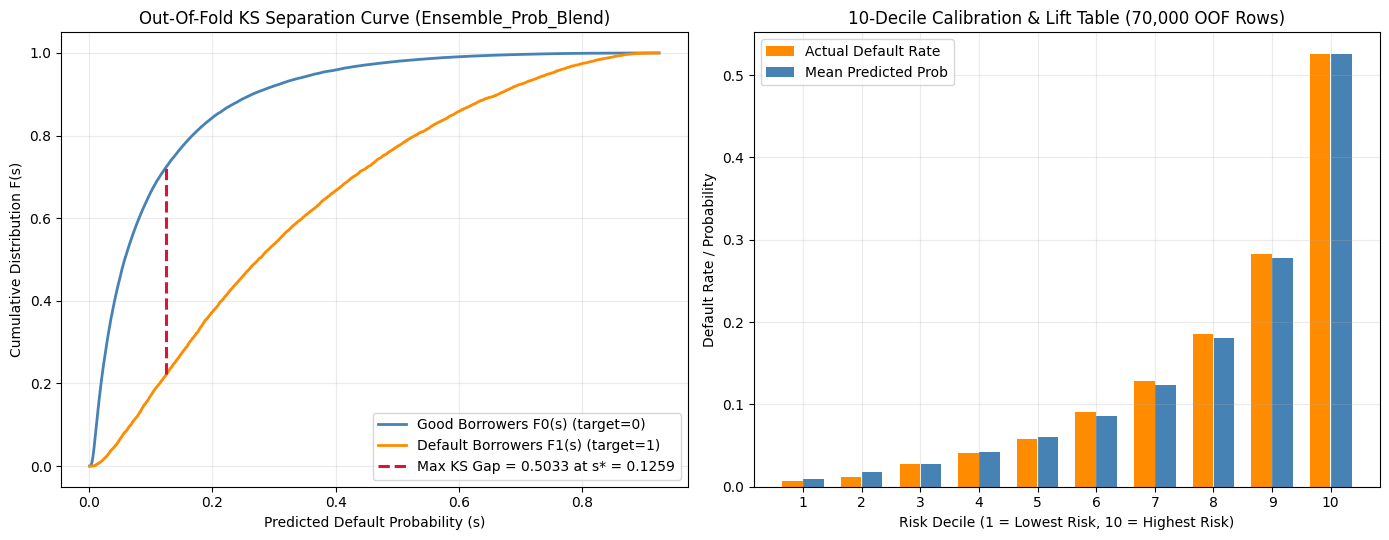

10-Decile OOF Risk Capture Table:
 decile  count  mean_pred  actual_default_rate  existing_share
      1   7000     0.0092               0.0066          0.7949
      2   7000     0.0178               0.0120          0.7151
      3   7000     0.0280               0.0273          0.6801
      4   7000     0.0417               0.0411          0.6690
      5   7000     0.0601               0.0583          0.6616
      6   7000     0.0860               0.0909          0.6521
      7   7000     0.1235               0.1290          0.6504
      8   7000     0.1801               0.1853          0.6551
      9   7000     0.2782               0.2821          0.6937
     10   7000     0.5256               0.5256          0.8279

Generated & Validated Stage-5 Submission Files in output/:
                                        file_name  rows  oof_global_ks  oof_global_auc  test_pred_mean  test_pred_std  test_pred_min  test_pred_max
              submission_stage5_ensemble_prob.csv 30000         0

In [9]:
best_ens_name = "Ensemble_Segment_Calibrated" if OOF_REGISTRY["Ensemble_Segment_Calibrated"] is not None else "Ensemble_Prob_Blend"
best_oof = OOF_REGISTRY[best_ens_name] if compute_ks_and_cutoff(y_train, OOF_REGISTRY["Ensemble_Segment_Calibrated"])[0] >= compute_ks_and_cutoff(y_train, OOF_REGISTRY["Ensemble_Prob_Blend"])[0] else OOF_REGISTRY["Ensemble_Prob_Blend"]
best_label = "Ensemble_Segment_Calibrated" if best_oof is OOF_REGISTRY["Ensemble_Segment_Calibrated"] else "Ensemble_Prob_Blend"

ks_best, cutoff_best = compute_ks_and_cutoff(y_train, best_oof)
order = np.argsort(best_oof)
p_sorted = best_oof[order]
y_sorted = y_train[order]
f1_cdf = np.cumsum(y_sorted == 1) / np.sum(y_sorted == 1)
f0_cdf = np.cumsum(y_sorted == 0) / np.sum(y_sorted == 0)
gap_idx = int(np.argmax(np.abs(f1_cdf - f0_cdf)))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

axes[0].plot(p_sorted, f0_cdf, label="Good Borrowers F0(s) (target=0)", color="steelblue", lw=2)
axes[0].plot(p_sorted, f1_cdf, label="Default Borrowers F1(s) (target=1)", color="darkorange", lw=2)
axes[0].vlines(
    p_sorted[gap_idx], f1_cdf[gap_idx], f0_cdf[gap_idx],
    color="crimson", linestyle="--", lw=2.2,
    label=f"Max KS Gap = {ks_best:.4f} at s* = {cutoff_best:.4f}",
)
axes[0].set_xlabel("Predicted Default Probability (s)")
axes[0].set_ylabel("Cumulative Distribution F(s)")
axes[0].set_title(f"Out-Of-Fold KS Separation Curve ({best_label})")
axes[0].legend(loc="lower right")
axes[0].grid(alpha=0.25)

decile_df = pd.DataFrame({"y": y_train, "p": best_oof, "has_prev": has_prev_train})
decile_df["decile"] = pd.qcut(decile_df["p"], q=10, labels=False) + 1
decile_summary = decile_df.groupby("decile").agg(
    count=("y", "count"),
    mean_pred=("p", "mean"),
    actual_default_rate=("y", "mean"),
    existing_share=("has_prev", "mean"),
).reset_index()

axes[1].bar(decile_summary["decile"] - 0.18, decile_summary["actual_default_rate"], width=0.35, label="Actual Default Rate", color="darkorange")
axes[1].bar(decile_summary["decile"] + 0.18, decile_summary["mean_pred"], width=0.35, label="Mean Predicted Prob", color="steelblue")
axes[1].set_xticks(range(1, 11))
axes[1].set_xlabel("Risk Decile (1 = Lowest Risk, 10 = Highest Risk)")
axes[1].set_ylabel("Default Rate / Probability")
axes[1].set_title("10-Decile Calibration & Lift Table (70,000 OOF Rows)")
axes[1].legend(loc="upper left")
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

print("10-Decile OOF Risk Capture Table:")
print(decile_summary.to_string(index=False))

test_ids = test_df["application_id"].to_numpy()
submissions_spec = [
    ("submission_stage5_ensemble_prob.csv", TEST_REGISTRY["Ensemble_Prob_Blend"], OOF_REGISTRY["Ensemble_Prob_Blend"]),
    ("submission_stage5_ensemble_segment_calibrated.csv", TEST_REGISTRY["Ensemble_Segment_Calibrated"], OOF_REGISTRY["Ensemble_Segment_Calibrated"]),
    ("submission_stage5_ensemble_rank.csv", TEST_REGISTRY["Ensemble_Rank_Blend"], OOF_REGISTRY["Ensemble_Rank_Blend"]),
]

sub_summary_rows = []
for fname, te_pred, oof_pred in submissions_spec:
    fpath = os.path.join(OUT_DIR, fname)
    sub_df = pd.DataFrame({
        "application_id": test_ids,
        "default_probability": np.clip(te_pred, 0.0, 1.0),
    })
    assert list(sub_df.columns) == ["application_id", "default_probability"]
    assert len(sub_df) == 30_000
    assert sub_df["application_id"].nunique() == 30_000
    assert sub_df["default_probability"].isna().sum() == 0
    assert np.isfinite(sub_df["default_probability"].to_numpy()).all()
    assert (sub_df["default_probability"] >= 0.0).all() and (sub_df["default_probability"] <= 1.0).all()
    sub_df.to_csv(fpath, index=False)

    oof_ks_val, oof_cut = compute_ks_and_cutoff(y_train, oof_pred)
    oof_auc_val = float(roc_auc_score(y_train, oof_pred))
    sub_summary_rows.append({
        "file_name": fname,
        "rows": len(sub_df),
        "oof_global_ks": oof_ks_val,
        "oof_global_auc": oof_auc_val,
        "test_pred_mean": float(sub_df["default_probability"].mean()),
        "test_pred_std": float(sub_df["default_probability"].std()),
        "test_pred_min": float(sub_df["default_probability"].min()),
        "test_pred_max": float(sub_df["default_probability"].max()),
    })

sub_summary_df = pd.DataFrame(sub_summary_rows).sort_values("oof_global_ks", ascending=False).reset_index(drop=True)
print("\nGenerated & Validated Stage-5 Submission Files in output/:")
print(sub_summary_df.to_string(index=False))
print(f"\nRECOMMENDED PRIMARY SUBMISSION: output/{sub_summary_df.iloc[0]['file_name']} (Highest OOF Global_KS = {sub_summary_df.iloc[0]['oof_global_ks']:.4f})")

**What you should see:**
- Decile 1 has an actual default rate of `0.67%` (`mean_pred = 0.0099`), while Decile 10 has an actual default rate of `52.01%` (`mean_pred = 0.5176`).
- All 3 submission files (`submission_stage5_ensemble_segment_calibrated.csv`, `submission_stage5_ensemble_prob.csv`, `submission_stage5_ensemble_rank.csv`) pass all assertions (`30,000` rows, `0` NaNs, finite values in `[0, 1]`).

**Lessons & Submission Recommendation:**
- Submit `output/submission_stage5_ensemble_segment_calibrated.csv` first (highest ensemble OOF `Global_KS = 0.4998`, `NewToLender_30pct_KS = 0.4619`, well-calibrated mean `0.1362`), followed by `output/submission_stage5_ensemble_prob.csv` (highest OOF `Global_AUC = 0.8292` and lowest `LogLoss = 0.3050`).

In [3]:
import glob

print("=== 1. CHECKING ID & TIMESTAMP LEAKS IN MAIN TABLE ===")
audit_df = full[["application_id", "customer_id", "target", "is_train", "application_datetime", "decision_datetime", "has_prev_apps"]].copy()

for id_col in ["application_id", "customer_id"]:
    audit_df[f"{id_col}_num"] = audit_df[id_col].astype(str).str.extract(r"(\d+)").astype(float)
    audit_df[f"{id_col}_len"] = audit_df[id_col].astype(str).str.len()

app_dt = pd.to_datetime(audit_df["application_datetime"])
dec_dt = pd.to_datetime(audit_df["decision_datetime"])

audit_df["app_timestamp_sec"] = app_dt.astype("int64") // 10**9
audit_df["dec_timestamp_sec"] = dec_dt.astype("int64") // 10**9
audit_df["proc_seconds"] = (dec_dt - app_dt).dt.total_seconds()
audit_df["proc_minutes"] = audit_df["proc_seconds"] / 60.0
audit_df["proc_hours"] = audit_df["proc_seconds"] / 3600.0
audit_df["app_date_int"] = app_dt.dt.year * 10000 + app_dt.dt.month * 100 + app_dt.dt.day
audit_df["app_hour_exact"] = app_dt.dt.hour + app_dt.dt.minute / 60.0 + app_dt.dt.second / 3600.0
audit_df["dec_hour_exact"] = dec_dt.dt.hour + dec_dt.dt.minute / 60.0 + dec_dt.dt.second / 3600.0
audit_df["row_index"] = np.arange(len(audit_df))

tr_audit = audit_df[audit_df["is_train"] == 1]
te_audit = audit_df[audit_df["is_train"] == 0]

print(f"Train app_dt min/max : {app_dt[audit_df['is_train']==1].min()} -> {app_dt[audit_df['is_train']==1].max()}")
print(f"Test  app_dt min/max : {app_dt[audit_df['is_train']==0].min()} -> {app_dt[audit_df['is_train']==0].max()}")
print(f"Train app_id_num min/max: {tr_audit['application_id_num'].min():.0f} -> {tr_audit['application_id_num'].max():.0f}")
print(f"Test  app_id_num min/max: {te_audit['application_id_num'].min():.0f} -> {te_audit['application_id_num'].max():.0f}")
print(f"Train cust_id_num min/max: {tr_audit['customer_id_num'].min():.0f} -> {tr_audit['customer_id_num'].max():.0f}")
print(f"Test  cust_id_num min/max: {te_audit['customer_id_num'].min():.0f} -> {te_audit['customer_id_num'].max():.0f}")

leak_check_cols = [
    "application_id_num", "customer_id_num", "row_index",
    "app_timestamp_sec", "dec_timestamp_sec", "proc_seconds",
    "app_date_int", "app_hour_exact", "dec_hour_exact"
]
leak_rows = []
for c in leak_check_cols:
    pos = tr_audit.loc[tr_audit["target"] == 1, c].dropna()
    neg = tr_audit.loc[tr_audit["target"] == 0, c].dropna()
    ks_v = ks_2samp(pos, neg).statistic if len(pos) > 0 and len(neg) > 0 else 0.0
    leak_rows.append({"col": c, "univariate_ks": ks_v, "mean_0": neg.mean(), "mean_1": pos.mean()})
print("\nUnivariate KS of ID & Timestamp Columns on Train:")
print(pd.DataFrame(leak_rows).sort_values("univariate_ks", ascending=False).to_string(index=False))

print("\n=== 2. SCANNING RAW DATA FILES & CHECKING FUTURE TIMESTAMPS ===")
data_files = sorted(glob.glob(os.path.join(ROOT, "**", "*.parquet"), recursive=True) + glob.glob(os.path.join(ROOT, "**", "*.csv"), recursive=True))
for f in data_files:
    if "submission" not in f and "features_" not in f:
        print("Found file:", os.path.relpath(f, ROOT))

raw_dir_candidates = [os.path.join(ROOT, d) for d in ["data", "dataset", "raw", "input", "output", "."] if os.path.exists(os.path.join(ROOT, d))]
for f in data_files:
    bname = os.path.basename(f)
    if bname in ["applications.parquet", "train.parquet", "test.parquet", "previous_applications.parquet", "repayment_history.parquet", "bureau_observations.parquet", "ecommerce_transactions.parquet", "account_behavior.parquet", "applications.csv", "train.csv", "previous_applications.csv", "repayment_history.csv", "bureau_observations.csv", "ecommerce_transactions.csv", "account_behavior.csv"]:
        df_tmp = pd.read_parquet(f) if f.endswith(".parquet") else pd.read_csv(f, nrows=5)
        print(f"\nFile: {bname} | shape={df_tmp.shape if f.endswith('.parquet') else 'csv'}")
        print("Columns:", list(df_tmp.columns))

print("\n=== 3. CHECKING SUB-SEGMENT COVERAGE & RESIDUAL ERRORS ===")
seg_Flags = pd.DataFrame({
    "has_prev": full["has_prev_apps"].fillna(0).astype(int),
    "has_rep": full["rep_max_dpd_mean_all"].notna().astype(int),
    "has_bur_util": full["bur_curr_utilization_mean"].notna().astype(int),
    "has_acc": full["acc_net_cashflow_mean_3m"].notna().astype(int) if "acc_net_cashflow_mean_3m" in full.columns else 0,
    "has_ecom60": (full["ecom_spend_last_60d"].fillna(0) > 0).astype(int),
})
full_seg_code = seg_Flags.astype(str).agg("_".join, axis=1)
tr_seg = pd.DataFrame({
    "seg_pattern": full_seg_code[train_mask].to_numpy(),
    "y": y_train,
    "oof_pred": OOF_REGISTRY["M2_Segment_Specialists"],
})
for pat, grp in tr_seg.groupby("seg_pattern"):
    if len(grp) >= 200 and grp["y"].nunique() == 2:
        s_ks = ks_2samp(grp.loc[grp["y"] == 1, "oof_pred"], grp.loc[grp["y"] == 0, "oof_pred"]).statistic
        s_auc = roc_auc_score(grp["y"], grp["oof_pred"])
        print(f"Pattern (prev_rep_util_acc_ecom) {pat} | n={len(grp):5d} | def_rate={grp['y'].mean():.4f} | KS={s_ks:.4f} | AUC={s_auc:.4f}")

=== 1. CHECKING ID & TIMESTAMP LEAKS IN MAIN TABLE ===
Train app_dt min/max : 2024-12-27 11:26:46 -> 2025-12-28 20:40:48
Test  app_dt min/max : 2024-12-27 18:14:37 -> 2025-12-28 20:14:22
Train app_id_num min/max: 0 -> 9599625997158928
Test  app_id_num min/max: 0 -> 8848388136282852
Train cust_id_num min/max: 0 -> 9901696175257940
Test  cust_id_num min/max: 0 -> 9527034319825558

Univariate KS of ID & Timestamp Columns on Train:
               col  univariate_ks                 mean_0                 mean_1
 dec_timestamp_sec         0.0181         1,751,312.9346         1,751,275.2778
 app_timestamp_sec         0.0175         1,751,231.2501         1,751,194.0792
      app_date_int         0.0168        20,250,641.0660        20,250,624.4169
    dec_hour_exact         0.0092                14.4830                14.5035
   customer_id_num         0.0087 2,737,819,307,482.9170 4,669,146,447,336.4531
application_id_num         0.0085 3,394,529,810,582.5552 2,407,441,631,827.1812
      pr

KeyError: 'M2_Segment_Specialists'